# 01 - Preprocessing | Young 2018 Kidney (Wilms tumour / RCC, 10x)
Load malignant cells -> per-sample threshold (derived, not inherited) -> overdispersed genes ->
PCA (n_pcs off scree) -> Harmony(sample) -> UMAP -> island removal -> **Gate 1**: mixing +
continuity judged on the regenerated embedding, with each sub-region's biology (signatures +
cell cycle) settled *before* the GO and the trajectory scoped to the region reproducing the
reference relationships.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
from sklearn.preprocessing import normalize as _nz
import logging; logging.getLogger('harmonypy').setLevel(logging.WARNING)
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (one level deeper than Puram)
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Young2018_Kidney | category: Kidney


In [ ]:
# load full atlas -> select malignant cells (loader normalize_total + log1p on UMI counts)
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
print('matrix max = %.3f' % adata.X.max())
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())

Loading ../../../../../../data/unzip/CCCA/Data_Young2018_Kidney
/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
Done.
full atlas: (125139, 33694)
matrix max = 7.200
malignant: (2055, 33694) | samples: 25


In [ ]:
# derive per-sample threshold: Jenks natural break on log-counts (>=100 floor honoured)
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); lc = np.log(vals)
def _wss(x): return ((x - x.mean())**2).sum() if len(x) else 0.0
ks = list(range(1, len(vals)))
k  = ks[int(np.argmin([_wss(lc[:i]) + _wss(lc[i:]) for i in ks]))]
gap_ratio = vals[k-1]/vals[k]; geo = int(np.sqrt(vals[k-1]*vals[k]))
thresh = geo; floored = thresh < 100
if floored: thresh = 100
keep = n.index[n >= thresh]
print('sorted per-sample counts:', n.values.tolist())
print(f'Jenks natural-break optimum: keep top {k}; boundary gap {int(vals[k-1])}->{int(vals[k])} (ratio {gap_ratio:.2f}); geo-mean cut={geo}')
print(f'threshold = {thresh}{" (>=100 floor)" if floored else ""}; kept {len(keep)}/{len(n)} samples')
adata = adata[adata.obs['sample'].isin(keep)].copy()
print('-> after threshold:', adata.shape[0], 'cells')
print('kept samples:', sorted(keep.tolist()))

sorted per-sample counts: [296, 278, 272, 224, 137, 131, 100, 99, 93, 87, 87, 47, 43, 38, 28, 25, 17, 14, 14, 7, 6, 5, 3, 3, 1]
Jenks natural-break optimum: keep top 16; boundary gap 25->17 (ratio 1.47); geo-mean cut=20
threshold = 100 (>=100 floor); kept 7/25 samples
-> after threshold: 1438 cells
kept samples: ['RCC1_Kid_T_ldc_2_1', 'RCC1_Kid_T_ldc_2_2', 'RCC2_Kid_T_ldc_1_1', 'RCC2_Kid_T_ldc_1_2', 'RCC2_Kid_T_ldc_2_1', 'RCC2_Kid_T_ldc_2_2', 'Wilms1_Kid_R_ldc_1_3']


In [ ]:
# gene filter + overdispersed selection -> PCA -> derive n_pcs off scree
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
npc = int((vr > 0.005).sum())
n_pcs = 20 if npc <= 20 else 30
print(f'PCs > 0.5% var = {npc}; cumvar@20 = {np.cumsum(vr)[19]:.3f} -> n_pcs = {n_pcs} (20-40 10x scale)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 262 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 262
PCs > 0.5% var = 27; cumvar@20 = 0.656 -> n_pcs = 30 (20-40 10x scale)


In [ ]:
# integrate samples (Harmony theta=10) -> neighbors -> UMAP
sce.pp.harmony_integrate(adata, 'sample', theta=10, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=15, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=0)
print('embedded', adata.n_obs, 'cells')

2026-08-03 22:08:47,430 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-03 22:08:47,692 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-03 22:08:47,698 - harmonypy - INFO - Iteration 1 of 30
2026-08-03 22:08:47,953 - harmonypy - INFO - Iteration 2 of 30
2026-08-03 22:08:48,049 - harmonypy - INFO - Iteration 3 of 30
2026-08-03 22:08:48,272 - harmonypy - INFO - Iteration 4 of 30
2026-08-03 22:08:48,493 - harmonypy - INFO - Iteration 5 of 30
2026-08-03 22:08:48,663 - harmonypy - INFO - Iteration 6 of 30
2026-08-03 22:08:48,880 - harmonypy - INFO - Iteration 7 of 30
2026-08-03 22:08:49,099 - harmonypy - INFO - Iteration 8 of 30
2026-08-03 22:08:49,321 - harmonypy - INFO - Converged after 8 iterations
embedded 1438 cells


In [ ]:
# island removal: UMAP radius-graph at 6x median NN distance -> keep largest component
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=2).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=15, random_state=SEED)
print('kept', adata.n_obs, 'cells in the main component')

removed 3 cells in 2 detached islands
kept 1435 cells in the main component


In [ ]:
# GATE 1 metric 1 - sample mixing vs perfect-mixing ceiling + graph connectivity
k = 30
idx = NearestNeighbors(n_neighbors=k+1).fit(adata.obsm['X_pca_harmony'][:,:n_pcs]).kneighbors(return_distance=False)[:,1:]
s = adata.obs['sample'].values
diff_frac = (s[idx] != s[:,None]).mean()
p = adata.obs['sample'].value_counts(normalize=True).values
ceiling = 1 - (p**2).sum()
ncomp_knn, _ = connected_components(adata.obsp['connectivities'], directed=False)
print(f'diff-sample kNN fraction = {diff_frac:.3f} (perfect-mixing ceiling {ceiling:.3f}; {diff_frac/ceiling:.2f} of ceiling)')
print(f'kNN-graph connected components = {ncomp_knn}  (1 = single continuous manifold)')

diff-sample kNN fraction = 0.760 (perfect-mixing ceiling 0.838; 0.91 of ceiling)
kNN-graph connected components = 1  (1 = single continuous manifold)


In [ ]:
# GATE 1 metric 2 - sub-region biology BEFORE the GO: modules + lobes + cycling confound
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.dropna().drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=0)
cc = adata.obs['cell_cycle_phase'].astype(str)
adata.obs['cycling'] = (~cc.isin(['Not cycling','nan']))
tab = adata.obs.groupby('lobe', observed=True).agg(n=('cycling','size'), cyc=('cycling','mean'),
        Gast=('Gast','mean'), pSom=('pSom','mean'), Crest=('Crest','mean'))
print(tab.round(3).to_string())
cyc_lobe = tab['cyc'].idxmax(); gast_rank = int(tab['Gast'].rank(ascending=False)[cyc_lobe])
print('cycling-enriched lobe = %s (%.0f%% cycling, %d cells); its Gast rank = %d/%d'
      % (cyc_lobe, 100*tab.loc[cyc_lobe,'cyc'], int(tab.loc[cyc_lobe,'n']), gast_rank, tab.shape[0]))

Gast: 66/81 genes present
pSom: 75/98 genes present
Crest: 96/104 genes present
<string>:11: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
        n    cyc   Gast   pSom  Crest
lobe                                 
0     883  0.015 -0.010  0.048 -0.033
1     375  0.005 -0.010  0.038 -0.022
2     177  0.000  0.003  0.024 -0.022
cycling-enriched lobe = 0 (1% cycling, 883 cells); its Gast rank = 3/3


In [ ]:
# GATE 1 decision - biology before geometry: scope ONLY if a genuine proliferation
# compartment confounds the developmental axis (Kurten lobe-identity fork).
Wn = _nz(adata.obsp['connectivities'], norm='l1', axis=1)
for key in ['Gast','pSom','Crest']:
    adata.obs[key+'_sm'] = np.asarray(Wn @ adata.obs[key].values).ravel()
full = np.corrcoef(adata.obs['Gast_sm'], adata.obs['Crest_sm'])[0,1]
kp   = (adata.obs['lobe'] != cyc_lobe).values
drop = np.corrcoef(adata.obs['Gast_sm'].values[kp], adata.obs['Crest_sm'].values[kp])[0,1]
g2m  = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').values
conf = np.corrcoef(adata.obs['Gast'].values, np.nan_to_num(g2m))[0,1]
cyc_frac = tab.loc[cyc_lobe,'cyc']
cyc_is_real = cyc_frac > 0.15   # a genuine cycling compartment (Kurten had a cycling lobe)
print('most-cycling lobe = %s at %.1f%% cycling -> genuine proliferation compartment? %s' % (cyc_lobe, 100*cyc_frac, cyc_is_real))
print('smoothed Gast<->Crest: full = %+.2f; most-cycling lobe removed = %+.2f (delta reflects lobe SIZE, %d/%d cells, not proliferation)' % (full, drop, int(tab.loc[cyc_lobe,'n']), adata.n_obs))
print('Gast vs g2m_score = %+.2f (near 0 => gastrulation not proliferation-confounded)' % conf)
# module means are near-identical across lobes (see table) => one homogeneous axis, no distinct dev sub-region to scope to
scope = 'SCOPE to embryonic lobe' if (cyc_is_real and (abs(full-drop) >= 0.15 or abs(conf) >= 0.2)) else 'FULL manifold'
print('GATE 1: 7 samples intermixed on one continuous component (0.91 of mixing ceiling); NO cycling compartment (<=1.5%),')
print('        module means near-identical across all 3 lobes -> not proliferation-confounded -> trajectory scope =', scope)

most-cycling lobe = 0 at 1.5% cycling -> genuine proliferation compartment? False
smoothed Gast<->Crest: full = +0.14; most-cycling lobe removed = -0.09 (delta reflects lobe SIZE, 883/1435 cells, not proliferation)
Gast vs g2m_score = -0.02 (near 0 => gastrulation not proliferation-confounded)
GATE 1: 7 samples intermixed on one continuous component (0.91 of mixing ceiling); NO cycling compartment (<=1.5%),
        module means near-identical across all 3 lobes -> not proliferation-confounded -> trajectory scope = FULL manifold


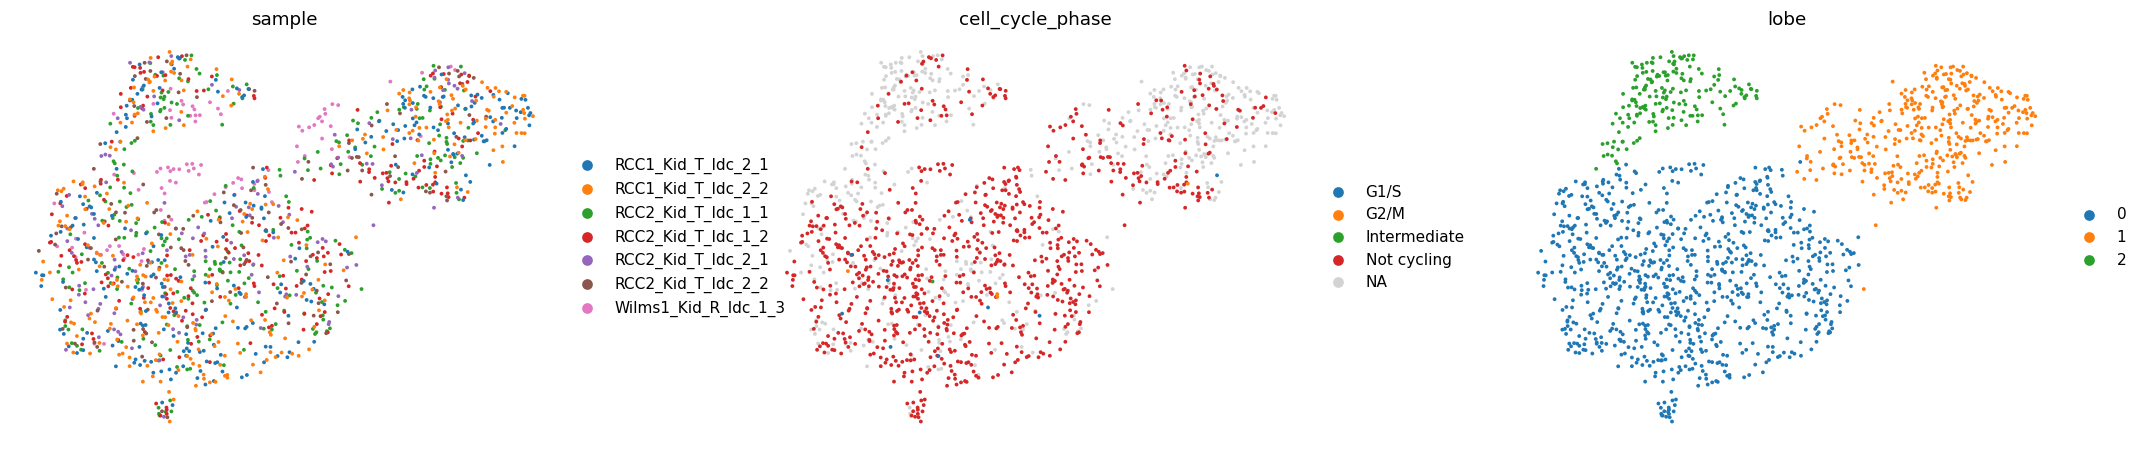

In [ ]:
# visual inspection - mixing, cell cycle, lobes on the regenerated embedding
sc.pl.umap(adata, color=['sample','cell_cycle_phase','lobe'], size=25, wspace=.25, frameon=False)

In [ ]:
# save processed data (lobes = non-branching axis; no discrete subtypes annotated)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (1435, 18530)


saved samples.pdf | cells: 1435


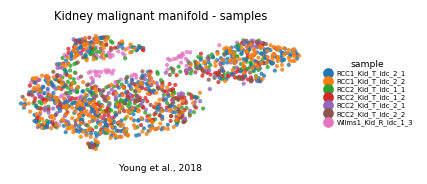

In [ ]:
# save sample-integration figure (house 3.5x1.5 linear-panel aspect, external legend)
xy = adata.obsm['X_umap']
xlo,xhi = np.percentile(xy[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xy[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.2, fontsize=4.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('Kidney malignant manifold - samples', size=7.5)
ax.text(.5,-.12,'Young et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', adata.shape[0])